The most common sequence-to-sequence (seq2seq) models are encoder-decoder models, which encode the source (input) sentence into a single vector we called context vector. We can think of the context vector as being an abstract representation of the entire input sentence(summary representation). This vector is then decoded by a second RNN which learns to output the target (output) sentence by generating it one word at a time.

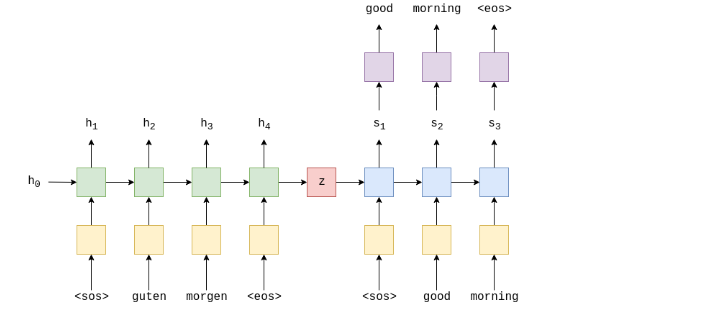

The above image shows an example translation. The input/source sentence, "guten morgen", is passed through the embedding layer (yellow) and then input into the encoder (green).

We also append a start of sequence `<sos>` and end of sequence `<eos>` token to the start and end of sentence, respectively. At each time-step, the input to the encoder RNN is both the embedding, `e`, of the current word,
$e(x_t)$, as well as the hidden state from the previous time-step, $h_{t-1}$, and the encoder RNN outputs a new hidden state $h_t$. We can think of the hidden state as a vector representation of the sentence so far. The RNN can be represented as a function of both of $e(x_t)$ and $h_{t-1}$:


$h_t = EncoderRNN(e(x_t), h_{t-1})$


We're using the term RNN generally here, it could be any recurrent architecture, such as an LSTM (Long Short-Term Memory) or a GRU (Gated Recurrent Unit). Here, we have X = {$x_1, x_2,...,x_T$}, where $x_1$=sos, $x_2$=guten, etc. The initial hidden state, $h_0$, is usually either initialized to zeros or a learned parameter.

Once the final word, $x_T$, has been passed into the RNN, we use the final hidden state, $h_T$, as the context vector, i.e. $h_T=z$. This is a vector representation of the entire source sentence.

Now we have our context vector, $z$, we can start decoding it to get the output/target sentence, "good morning". Again, we append start and end of sequence tokens to the target sentence. At each time-step, the input to the decoder RNN (blue) is the embedding, $d$, of current word, $d(y_t)$, as well as the hidden state from the previous time-step, $s_{t-1}$, where the initial decoder hidden state, $S_0$, is the context vector, $s_0 = z = h_T$ , i.e. the initial decoder hidden state is the final encoder hidden state. Thus, similar to the encoder, we can represent the decoder as:

$s_t = DecoderRNN(d(y_t), s_{t-1})$

Although the input/source embedding layer, $e$, and the output/target embedding layer, $d$, are both shown in yellow in the diagram they are two different embedding layers with their own parameters.

In the decoder, we need to go from the hidden state to an actual word, therefore at each time-step we use $s_t$ to predict (by passing it through a Linear layer, shown in purple) what we think is the next word in the sequence,
$\hat{y_t} = f(s_t)$.


The words in the decoder are always generated one after another, with one per time-step. We always use sos for the first input to the decoder, $y_1$, but for subsequent inputs, $y_{t>1}$, we will sometimes use the actual, ground truth next word in the sequence, $y_t$ and sometimes use the word predicted by our decoder, $\hat{y}_{t-1}$. This is called teacher forcing/autoregressive respectively.

When training/testing our model, we always know how many words are in our target sentence, so we stop generating words once we hit that many. During inference it is common to keep generating words until the model outputs an <eos> token or after a certain amount of words have been generated.

Once we have our predicted target sentence, $\hat{Y}$ = {$\hat{y}_1,\hat{y}_2,...\hat{y}_T$}, we compare it against our actual target sentence, $Y$ = {${y}_1,{y}_2,...{y}_T$}, to calculate our loss. We then use this loss to update all of the parameters in our model.

### **Encoder–Decoder Architecture:**

Used for tasks where input and output are sequences (e.g., translation).

* **Encoder**: Processes input sequence into a **context vector** (or a sequence of hidden states).
* **Decoder**: Takes the context and **generates output token-by-token**.

---

## 1. What is **Auto-Regressive Decoding**?

**Definition**:
In auto-regressive decoding, each output token by decoder is generated **based on its previously generated tokens**.

Formally:

$$
P(y_1, y_2, ..., y_T | x) = \prod_{t=1}^{T} P(y_t | y_{<t}, x)
$$

* Used in: GPT, Transformer decoders, RNN decoders, etc.
* Applied in: **inference** (and optionally in training)

**Key Point**: The model relies on its **own previous outputs** at each step to generate the next token.

---

## 2. What is the problem with auto-regressive inference?

* If the model makes a mistake early on, that mistake propagates.
* Early prediction errors compound over time — known as **exposure bias** (model never learned to recover from its own mistakes during training).

---

## 3. What is **Teacher Forcing**?

**Definition**:
During training, instead of feeding the decoder its own previous prediction $\hat{y}_{t-1}$, we feed the **actual ground-truth token** $y_{t-1}$ from the dataset.

So:

$$
\text{Input at time } t = y_{t-1}^{\text{ground truth}} \quad \text{(not model's guess)}
$$

* Used only during: **training**
* Helps **speed up convergence** and **prevent error accumulation**

➡️ **But**: At inference time, **teacher forcing is not available** (no ground truth). That’s where the model must decode **auto-regressively** using its own predictions.


Teacher forcing is a training technique used with sequence-to-sequence models, like recurrent neural networks (RNNs) and transformers, where the true output sequence is fed back into the model(decoder) as input at each step during training. This forces the model to learn the correct sequence by imitating the "teacher" (the ground truth data).

In traditional training, the model's previous output is used as input for the next time step(auto-regressive). This can lead to errors accumulating over time, especially if the model makes early mistakes. Teacher forcing aims to mitigate this by feeding the correct output from the training data as input.

During training, the model receives the correct output (target sequence) from the training data as input at each step. This is different from the model's own predicted output.

Teacher forcing can improve the model's ability to learn long sequences and can help to prevent the model from getting stuck in incorrect predictions. It also simplifies the training process by reducing the complexity of the gradient landscape, especially for long sequences.

A potential drawback of teacher forcing is that it can lead to a "train-test gap" because the model's input during training (the ground truth) is different from the input it receives during inference (its own predictions). To address this, a common strategy is to gradually reduce the level of teacher forcing during training, allowing the model to learn to generate its own outputs based on its previous predictions

---



**decoding strategies**—how models generate sequences at **inference time**, especially in **auto-regressive settings** like machine translation, summarization, and text generation.

---

## **The Big Picture: Decoding in Sequence Generation**

When a model (like a Transformer or RNN decoder) is generating a sequence one token at a time, it has to **choose the next token** from a probability distribution over the vocabulary. But how does it decide?

That’s where **decoding strategies** come in.

---

## 1. **Greedy Decoding**

### What it is:

At each step, choose the token with the **highest probability**.

$$
\hat{y}_t = \arg\max_{y \in V} P(y | \hat{y}_{<t}, x)
$$

### Pros:

* Very fast
* Simple to implement

### Cons:

* **Locally optimal, globally suboptimal** — doesn't consider future possibilities
* Often leads to **bland or repetitive** outputs

---

## 2. **Beam Search**

### What it is:

Keeps the **top `k` partial sequences (beams)** at each time step, where `k = beam width`.

### How it works:

* At each time step:

  * Expand each current sequence with all possible next tokens
  * Keep only the top `k` **candidates** based on cumulative log-probability
* Continue until end-of-sequence (EOS) token

### Pros:

* Better than greedy in quality
* Balances **exploration vs. exploitation**

### Cons:

* More compute-heavy (k × vocab size at each step)
* May still miss diversity or get stuck in repetitive outputs

---

## 3. **Sampling**

### What it is:

Sample the next token from the probability distribution directly.

$$
y_t \sim P(y | y_{<t}, x)
$$

### Pros:

* Produces **more diverse and creative** outputs
* Good for open-ended generation (storytelling, dialogue)

### Cons:

* Can sample low-probability junk (nonsense)
* Unstable outputs

---

## 4. **Top‑k Sampling**

### What it is:

Sample from the **top `k` most probable tokens** only (truncate rest of vocab).

### Pros:

* Limits low-quality words
* Still retains diversity

---

## 5. **Top‑p (Nucleus) Sampling**

### 🔹 What it is:

Instead of a fixed k, choose the **smallest set of tokens** whose cumulative probability ≥ `p` (e.g., 0.9), and sample from there.

$$
\text{Nucleus} = \{ y_i : \sum_{j=1}^{i} P(y_j) \geq p \}
$$

### Pros:

* Adapts to uncertainty: larger pool for uncertain contexts, smaller for confident ones
* Balances quality and diversity better than top-k

---

## Other Concepts

### **Length Penalty (Beam Search)**

* Prevents model from favoring shorter sequences (which naturally have higher probabilities due to multiplication).
* Adjusts score like:

$$
\frac{\log P(y)}{(5 + |y|)^\alpha / (5+1)^\alpha}
$$

---

### **Diverse Beam Search**

* Adds diversity by penalizing similar sequences across beams
* Used in summarization or captioning to generate **varied** outputs

---

### **Repetition Penalty / Coverage Penalty**

* Helps avoid **repetitive loops** or **missing input segments** during generation

---

## When to Use What?

| Use Case                   | Recommended Decoding              |
| -------------------------- | --------------------------------- |
| Translation, summarization | Beam Search (with length penalty) |
| Chatbots, storytelling     | Top-p or Top-k sampling           |
| Fast & simple tasks        | Greedy decoding                   |
| Creative generation        | Sampling (with constraints)       |

---




### Example: Neural Machine Translation

* **Training**:
  - Encoder gets input sentence
  - Decoder is fed target tokens with combination of **teacher forcing** and autoregressive
  - Loss: Cross-entropy between predicted and ground-truth tokens

* **Inference**:
  - Start with `<BOS>` (beginning of sentence)
  - Decoder uses its **own past predictions** (auto-regressive)
  - Use **beam search** to find best output sequence

---



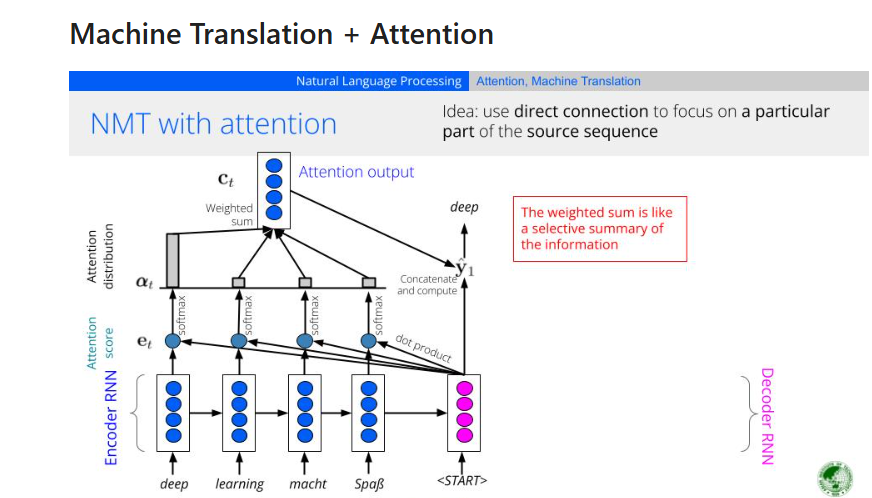

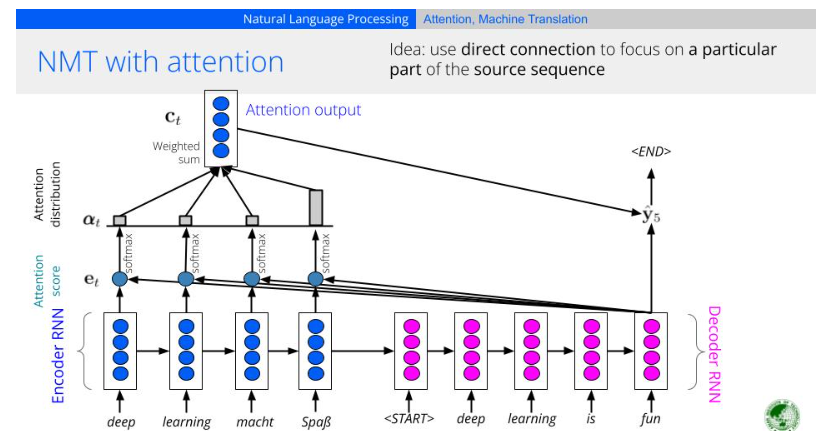

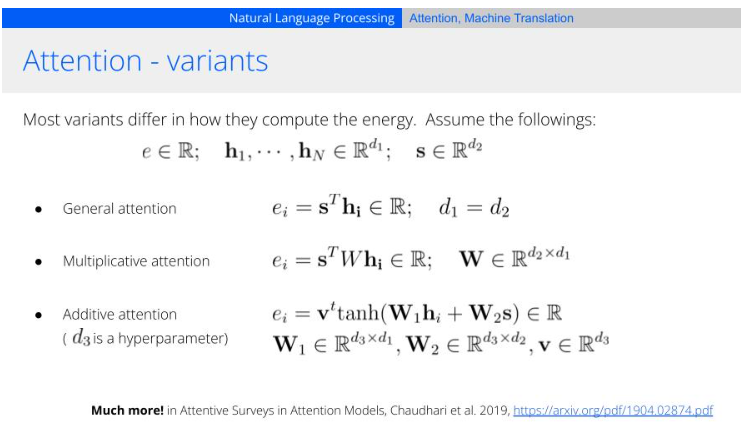

Here, we implement additive attention with GRU based encoder decoder model

In [2]:
!pip install torchtext torchdata --index-url https://download.pytorch.org/whl/cu118

Looking in indexes: https://download.pytorch.org/whl/cu118
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 30.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 811.7/811.7 MB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 121.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 105.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 875.6/875.6 kB 62.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 133.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 728.5/728.5 MB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.9/417.9 MB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.4/168.4 MB 7.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 MB 42.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.2/128.2 MB 20.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.1/20

In [3]:
!pip install "numpy<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 115.8 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.21.0+cu124 requires torch==2.6.0, but you have torch 2.2.0+cu118 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
torchtune 0.6.1 requires torchdata==0.11.0, but you have torchdata 0.7.1 which is incompatible.


In [4]:
!pip install portalocker>=2.0.0

### Dwonload the spacy English and German language model

In [5]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 121.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [6]:
!python -m spacy download de_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 122.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [1]:
import torch, torchtext

from torchtext.datasets import Multi30k

from torchtext.data.utils import get_tokenizer

from torchtext.vocab import build_vocab_from_iterator

from torch import nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

import random
import time

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Load Dataset

In [2]:
dataset = Multi30k(split="train", language_pair=("en", "de"))
dataset

ShardingFilterIterDataPipe

### EDA - Simple Investigation

In [3]:
sample = next(iter(dataset))
sample

('Two young, White males are outside near many bushes.',
 'Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.')

In [4]:
type(sample)

tuple

In [5]:
sample[0]

'Two young, White males are outside near many bushes.'

In [6]:
sample[1]

'Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.'

In [7]:
# Length
total_length = len(list(iter(dataset)))
total_length

/usr/local/lib/python3.11/dist-packages/torch/utils/data/datapipes/iter/combining.py:337: UserWarning: Some child DataPipes are not exhausted when __iter__ is called. We are resetting the buffer and each child DataPipe will read from the start again.
  warnings.warn("Some child DataPipes are not exhausted when __iter__ is called. We are resetting "


29001

#### Split the dataset

In [8]:
train, val, test = dataset.random_split(total_length=total_length, weights={"train": 0.7, "val": 0.2, "test": 0.1}, seed=SEED)

In [9]:
len(list(iter(train))), len(list(iter(val))), len(list(iter(test)))

(20301, 5800, 2900)

### Prepare the Dataset

In [10]:
# Constants
SRC_LANGUAGE = "en"
TARGET_LANGUAGE = "de"

#### Create Tokenizer

In [11]:
# We need 2 tokenizers to handle 2 different languages
src_tokenizer = get_tokenizer(tokenizer="spacy", language="en_core_web_sm")
target_tokenizer = get_tokenizer(tokenizer="spacy", language="de_core_news_sm")

# Create a dict that holds both tokenizers
tokenization_transform = {}
tokenization_transform[SRC_LANGUAGE] = src_tokenizer
tokenization_transform[TARGET_LANGUAGE] = target_tokenizer

tokenization_transform

{'en': functools.partial(<function _spacy_tokenize at 0x78275041bec0>, spacy=<spacy.lang.en.English object at 0x782669f7b110>),
 'de': functools.partial(<function _spacy_tokenize at 0x78275041bec0>, spacy=<spacy.lang.de.German object at 0x782666bae410>)}

In [12]:
# Test
print(tokenization_transform[SRC_LANGUAGE](sample[0]))

['Two', 'young', ',', 'White', 'males', 'are', 'outside', 'near', 'many', 'bushes', '.']


In [13]:
# Test
print(tokenization_transform[TARGET_LANGUAGE](sample[1]))

['Zwei', 'junge', 'weiße', 'Männer', 'sind', 'im', 'Freien', 'in', 'der', 'Nähe', 'vieler', 'Büsche', '.']


In [14]:
#  Helper function to yield list of tokens. Here data is a [(tuple(src, target)]
def yield_tokens(data, lang):
    lang_idxs = {SRC_LANGUAGE: 0, TARGET_LANGUAGE: 1}

    for sample in data:
        yield tokenization_transform[lang](sample[lang_idxs[lang]])  # Here lang = "en" or "de" where as SRC_LANGUAGE = "en", TARGET_LANGAUGE="de"

#### Numericalization

In [15]:
# Generate Vocab for source and target data

# Define special symbols and indices
specials = ["<unk>", "<pad>", "<sos>", "<eos>"]
UNK_IDX, PAD_IDX, SOS_IDX, EOS_IDX = 0, 1, 2, 3   # Make sure the tokens are in order of their indices to properly insert them in vocab

# Generate a dict that holds both source and target vocab
vocab_transform = {}
for lang in [SRC_LANGUAGE, TARGET_LANGUAGE]:
    vocab_transform[lang] = build_vocab_from_iterator(yield_tokens(train, lang), min_freq=2, specials=specials, special_first=True)

# Set UNK_IDX as the default idx. This idx is returned when the token is not found. If not set, it throws RuntimeError when the queried token is not found in the Vocabulary.
for lang in [SRC_LANGUAGE, TARGET_LANGUAGE]:
    vocab_transform[lang].set_default_index(UNK_IDX)

/usr/local/lib/python3.11/dist-packages/torch/utils/data/datapipes/iter/combining.py:337: UserWarning: Some child DataPipes are not exhausted when __iter__ is called. We are resetting the buffer and each child DataPipe will read from the start again.
  warnings.warn("Some child DataPipes are not exhausted when __iter__ is called. We are resetting "


In [16]:
type(vocab_transform[SRC_LANGUAGE])

torchtext.vocab.vocab.Vocab

In [17]:
# Unique vocab - (word2idx)
src_vocab_size = len(vocab_transform[SRC_LANGUAGE])
target_vocab_size = len(vocab_transform[TARGET_LANGUAGE])

src_vocab_size, target_vocab_size

(5207, 6464)

In [18]:
vocab_transform[SRC_LANGUAGE]["<unk>"]

0

In [19]:
vocab_transform[SRC_LANGUAGE]["<huyauhsink>"]

0

In [20]:
vocab_transform[SRC_LANGUAGE](["here", "is", "a", "unknownword", "word"])

[2587, 10, 4, 0, 3217]

In [21]:
vocab_transform[TARGET_LANGUAGE]["<unk>"]

0

In [22]:
# Reverse mapping (idx2word)
src_mapping = vocab_transform[SRC_LANGUAGE].get_itos()
target_mapping = vocab_transform[TARGET_LANGUAGE].get_itos()

In [23]:
src_mapping[0], src_mapping[1], src_mapping[2], src_mapping[3]

('<unk>', '<pad>', '<sos>', '<eos>')

In [24]:
src_mapping[5206]

'zooms'

In [25]:
target_mapping[0], target_mapping[1], target_mapping[2], target_mapping[3]

('<unk>', '<pad>', '<sos>', '<eos>')

In [26]:
target_mapping[6463]

'üppig'

#### Prepare the DataLoader

In [27]:
# Create Sequence transforms using decorator functionality - pipeline
def sequence_transform(*transforms):
    def func(text_input):
        for transform in transforms:
            text_input = transform(text_input)
        return text_input
    return func

def tensor_transform(tokens):
    """ADD <sos> and <eos> to the input sequnce idxs and return tensor"""
    return torch.cat((torch.tensor([SOS_IDX]), torch.tensor(tokens), torch.tensor([EOS_IDX])))


# src and target language text transforms to convert raw strings into tensors indices
transforms_pipe = {}
for lang in [SRC_LANGUAGE, TARGET_LANGUAGE]:
    transforms_pipe[lang] = sequence_transform(tokenization_transform[lang], # Tokenization
                                               vocab_transform[lang], # Numericalization
                                               tensor_transform) # Add BOS/EOS and create tensor

Note: *param in the function means, it can accept any number of positional arguments, and they will all be packed into a tuple called transforms.

In [28]:
# Collate Function
def collate_fn(batch):
    src_seqs, target_seqs, src_lengths = [], [], []
    for src_sample, target_sample in batch:
        processed_src = transforms_pipe[SRC_LANGUAGE](src_sample.rstrip("\n"))
        src_seqs.append(processed_src)
        src_lengths.append(processed_src.size(0))
        processed_target = transforms_pipe[TARGET_LANGUAGE](target_sample.rstrip("\n"))
        target_seqs.append(processed_target)
    src_batch = pad_sequence(src_seqs, padding_value=PAD_IDX)   # Note: batch_first is not set.
    target_batch = pad_sequence(target_seqs, padding_value=PAD_IDX)
    return src_batch, torch.tensor(src_lengths, dtype=torch.int64), target_batch

In [29]:
# Create DataLoaders
BATCH_SIZE = 64

train_dataloader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_dataloader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_dataloader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

In [54]:
# Test the dataloader
for src_en, src_len, target_de in train_dataloader:
    break

In [55]:
print("English shape: ", src_en.shape)  # (seq_len, batch_size)
print("German shape: ", target_de.shape)   # (seq_len, batch_size)
print(src_len.shape)

English shape:  torch.Size([24, 64])
German shape:  torch.Size([25, 64])
torch.Size([64])


### Model

In [32]:
class Encoder(nn.Module):
    def __init__(self, input_dim, embed_dim, hidden_dim, dropout):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, embed_dim, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(input_size=embed_dim, hidden_size=hidden_dim, num_layers=1, bidirectional=True)
        self.fc = nn.Linear(in_features=hidden_dim*2, out_features=hidden_dim)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, src_tokens_batch, src_lengths):
        embeds = self.dropout(self.embedding(src_tokens_batch))           # (seq_len, bs) -> (seq_len, bs, embed_dim)
        packed_embeds = pack_padded_sequence(embeds, lengths=src_lengths.to("cpu"), enforce_sorted=False)
        packed_outputs, hidden = self.rnn(packed_embeds)                  # hidden = (num layers * num directions, bs, hidden_dim)
        outputs, lengths = pad_packed_sequence(packed_outputs)            # outputs = (seq_len, bs, hidden_dim*2), lengths = (bs,)

        # concat the final forward (hidden[-2,:,:]) and backward (hidden[-1,:,:]) hidden layers to get the final hidden state
        hidden = torch.tanh(self.fc(torch.cat((hidden[-2, :, :], hidden[-1, :, :]), dim=1)))
        # (bs, hidden_dim) (bs, hidden_dim)  -> (bs, hidden_dim *2) -> (bs, hidden_dim)
        return outputs, hidden

The attention used here is additive attention which is defined by:

                    e = v tanh(Uh + Ws + b)

where h is encoder output hidden state, s is last hidden state return by encoder, v is used for weighted sum operation.

The forward method of attention takes a mask input which is a tensor of size (bs, src_seq_len). It ll have 1 when the source sentence token is not a padding token, and 0 when it is a padding token.

For eg, if the source sentence is: ["hello", "how", "are", "you", "?", , ], then the mask would be [1, 1, 1, 1, 1, 0, 0].

Note: We apply the mask after the attention has been calculated, but before it has been normalized by the softmax function.

Mask is applied using `masked_fill`. This fills the tensor where mask == 0 with the value -1e10.

In other words, it will take the un-normalized attention values, and change the attention values over padded elements to be -1e10. As these numbers will be miniscule compared to the other values they will become zero when passed through the softmax layer, ensuring no attention is payed to padding tokens in the source sentence.

In [40]:
class Attention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.v = nn.Linear(in_features=hidden_dim, out_features=1, bias=False)
        self.U = nn.Linear(in_features=hidden_dim * 2, out_features=hidden_dim)
        self.W = nn.Linear(in_features=hidden_dim, out_features=hidden_dim)

    def forward(self, hidden, encoder_outputs, mask):
        # encoder_outputs: (src_seq_len, bs, hidden_dim*2)  # context vector
        # hidden: (bs, hidden_dim)  # previous hidden state  # first hidden is basically the last hidden of the encoder and then decoder prev tokens hidden states
        bs = encoder_outputs.shape[1]
        src_seq_len = encoder_outputs.shape[0]

        # repeat the hidden src len times
        hidden = hidden.unsqueeze(dim=1).repeat(1, src_seq_len, 1)     # (bs, hidden_dim) -> (bs, 1, hidden_dim) -> (bs, src_seq_len, hidden_dim)
        encoder_outputs = encoder_outputs.permute(1, 0, 2)             # (src_seq_len, bs, hidden_dim*2) -> (bs, src_seq_len, hidden_dim*2)
        energy = self.v(torch.tanh(self.W(hidden) + self.U(encoder_outputs)))
        energy = energy.squeeze(dim=2)                                 # (bs, src_seq_len)
        # mask
        energy = energy.masked_fill(mask, -1e10)                       # apply padding mask # fills the true value in the mask with small value
        attn_dist = F.softmax(energy, dim=1)                           # (bs, src_seq_len)
        return attn_dist

Shapes:

self.U(encoder_outputs) -> (bs, src_seq_len, hidden_dim*2) -> (bs, src_seq_len, hidden_dim)

self.W(hidden) -> (bs, src_seq_len, hidden_dim) -> (bs, src_seq_len, hidden_dim)

torch.tanh(res1 + res2) -> (bs, src_seq_len, hidden_dim) + (bs, src_seq_len, hidden_dim) ->

self.v(result) (bs, src_seq_len, hidden_dim) -> (bs, src_seq_len, 1)

In [98]:
class Decoder(nn.Module):
    def __init__(self, output_dim, embed_dim, hidden_dim, dropout, attention):
        super().__init__()
        self.embedding = nn.Embedding(output_dim, embed_dim)  # output_dim is target vocab size
        self.rnn = nn.GRU(input_size=(hidden_dim * 2) + embed_dim, hidden_size=hidden_dim, bidirectional=False, num_layers=1) # takes encoder hidden and decoder input token
        self.fc = nn.Linear(in_features= (hidden_dim * 2) + embed_dim + hidden_dim, out_features=output_dim)  # we send token hidden dem, again encoder hidden dim and embed_dim to fc
        self.dropout = nn.Dropout(p=dropout)
        self.attention = attention
        self.output_dim = output_dim

    def forward(self, input_tokens, hidden, encoder_outputs, mask):
        # input_tokens -> (bs,)  # single token a time per seq
        # hidden -> (bs, hidden_dim)  # this is last hidden state from encoder for first token
        # encoder_outputs -> (src_seq_len, bs, hidden_dim * 2)
        # mask: (bs, src_seq_len)   # Note: mask is created later on in the model

        input_tokens = input_tokens.unsqueeze(dim=0)         # (bs,) -> (1, bs)
        embeds = self.dropout(self.embedding(input_tokens))  # (1, bs) -> (1, bs, embed_dim)

        attn = self.attention(hidden, encoder_outputs, mask)  # (bs, src_seq_len)
        attn = attn.unsqueeze(dim=1)                          # (bs, 1, src_seq_len)

        encoder_outputs = encoder_outputs.permute(1, 0, 2)    # (bs, src_seq_len, hidden_dim * 2)
        weighted_sum = torch.bmm(attn, encoder_outputs)       # (bs, 1, src_seq_len) (bs, src_seq_len, hidden_dim * 2) -> (bs, 1, hidden_dim *2)
        # This gives us, for each sample in the batch,
        # a weighted sum (context vector) across the
        # encoder’s hidden states.

        weighted_sum = weighted_sum.permute(1, 0, 2)           # (bs, 1, hidden_dim *2) -> (1, bs, hidden_dim *2)

        # concatenate (embed, weighted_encoder_outputs) and send the input to decoder rnn
        rnn_input = torch.cat((embeds, weighted_sum), dim=2)   # (1, bs, embed_dim) (1, bs, hidden_dim *2) => (1, bs, embed_dim + (hidden_dim*2))
        output, hidden = self.rnn(rnn_input, hidden.unsqueeze(dim=0))                   # output (1, bs, hidden_dim), hidden (1, bs, hidden_dim)

        # send the output of the decoder rnn to fc layer to predict the word => prediction = fc(concatenate (output, weighted, embed))
        embeds = embeds.squeeze(dim=0)
        weighted_sum = weighted_sum.squeeze(dim=0)
        output = output.squeeze(dim=0)
        prediction = self.fc(torch.cat((embeds, output, weighted_sum), dim=1))  # (bs, embed_dim + hidden *2 + hidden_dim) -> (bs, output_dim)
        return prediction, hidden.squeeze(0), attn.squeeze(dim=1)

## Big Picture: Decoder with Attention

### What happens at **each time step** in the decoder?

At every decoding step, the decoder:

1. Looks at its **previous hidden state** (from last step, or encoder's final state initially).
2. Uses **attention** to compute a **weighted combination of encoder outputs** (this is the `context vector`).
3. Feeds the **current target token embedding** and the **context vector** into the RNN (GRU/LSTM).
4. Produces a new **hidden state**, and uses it to predict the **next token**.

---

## Key Concepts and Their Roles

### 1. **Attention Weights (`attn`)**

Computed using:

```python
attn = Attention(hidden, encoder_outputs, mask)  # (bs, src_seq_len)
```

This tells us:
**"How much focus should we give to each token in the source sequence when decoding this step?"**

You compute it by comparing the decoder's current hidden state with **all** encoder outputs:

```python
energy = v(tanh(W(hidden) + U(encoder_outputs)))  # Score for each source position
```

This gives a score for **each encoder output**, and after softmax → **attention distribution** over source tokens.

---

### 2. **Weighted Sum = Context Vector**

```python
weighted_sum = torch.bmm(attn, encoder_outputs)
```

* This gives you a **context vector**: a **weighted average** of the encoder hidden states based on the attention weights.
* Think of this as:
  "A summary of the source sentence tailored for the current decoding step."

**Why?** Because the decoder doesn't have access to all source tokens — it asks the attention module:

> “Can you summarize the source for me based on where I should focus?”

---

### 3. **RNN + Context + Embed**

```python
rnn_input = torch.cat((embedding, weighted_sum), dim=2)
output, hidden = self.rnn(rnn_input)
```

* `embedding`: vector for current target token (ground truth or previous prediction)
* `weighted_sum`: the context vector from attention
* Together → RNN processes this and produces:

  * New `output`
  * New `hidden` (used for next decoding step)

---

### 4. **Prediction (FC layer)**

```python
prediction = fc(concat(embedding, output, context))
```

We combine the:

* Embedding (what we were decoding)
* RNN output (summary of this step)
* Context vector (summary of source focus)

...and pass it through a linear layer to get:

> A probability distribution over the vocabulary.

---

## So Why Use `encoder_outputs` Twice?

You're actually using it **once**, but in **two roles**:

| Use                         | Why                                                           |
| --------------------------- | ------------------------------------------------------------- |
| In Attention module         | To calculate **alignment scores** with current decoder hidden |
| In `torch.bmm` weighted sum | To compute the actual **context vector** (weighted average)   |

> You first score how relevant each encoder output is (with attention),
> then use those scores to combine them into a single vector (context).

---

## Is `weighted_sum` the next hidden state?

**No.**

* `weighted_sum` is the **context vector** (a representation of the source sentence focused for this time step).
* The **next hidden state** comes from the RNN:

  ```python
  output, hidden = self.rnn(rnn_input)
  ```

So you can think:

```
[Token embed] + [Context vector] → RNN → New Hidden State → Used for:
    - Next time step
    - Prediction now
```

---

## Summary Flow

```
At each decoding step:
----------------------------------------
1. embed = embedding(current_token)
2. attention_weights = attention(prev_hidden, encoder_outputs)
3. context = weighted_sum(attention_weights, encoder_outputs)
4. rnn_input = concat(embed, context)
5. output, hidden = GRU(rnn_input, prev_hidden)
6. prediction = FC(concat(embed, output, context))
7. Return prediction, hidden, attention_weights
```

---



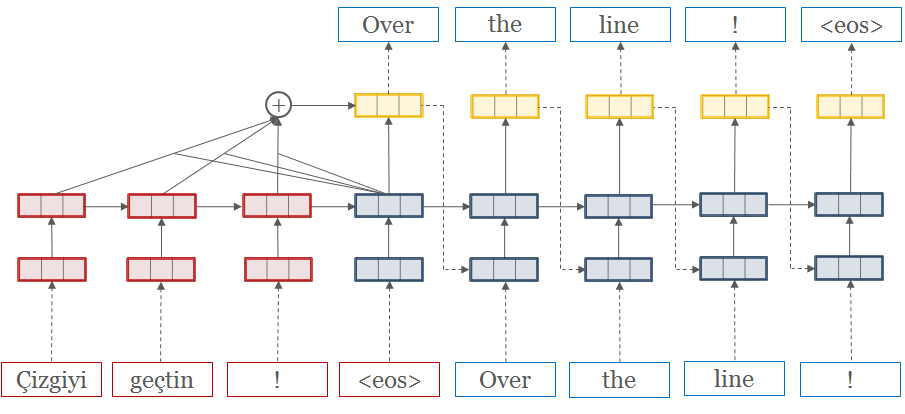

In [99]:
# Test Decoder
bs = 4
src_seq_len = 10
hidden_dim = 256
embed_dim = 128
output_dim = 1000
dropout = 0.5
attention = Attention(hidden_dim)

dummy_token = torch.randint(0, output_dim, (bs,))
dummy_hidden = torch.randn(bs, hidden_dim)
dummy_encoder_outputs = torch.randn(src_seq_len, bs, hidden_dim * 2)
dummy_mask = torch.randint(0, 2, (bs, src_seq_len)).bool()

decoder = Decoder(output_dim, embed_dim, hidden_dim, dropout, attention)
prediction, next_hidden, attn_weights = decoder(dummy_token, dummy_hidden, dummy_encoder_outputs, dummy_mask)


In [100]:
class Seq2SeqPckedAttnModel(nn.Module):
    def __init__(self, encoder, decoder, src_pad_idx, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_pad_idx = src_pad_idx
        self.device = device

    def create_mask(self, src_seq):
        # src_seq: (src_seq_len, bs)
        mask = (src_seq == self.src_pad_idx).permute(1, 0) # (bs, src_seq_len)  # permute so that it's the same shape as attention
        # eg mask: bs of (0, 0, 0, 0, 0, 1, 1)
        return mask

    def forward(self, src_seq, src_seq_len, target_seq, teacher_forcing_ratio=0.5):
        # src_seq: (src_seq, bs)
        # target: (target_seq, bs)
        # src_seq_len: (bs,)

        bs = src_seq.shape[1]
        src_len = src_seq.shape[0]
        target_seq_len = target_seq.shape[0]
        target_vocab_size = self.decoder.output_dim

        outputs = torch.zeros(target_seq_len, bs, target_vocab_size).to(self.device)
        attns = torch.zeros(target_seq_len, bs, src_len).to(self.device)

        # Encoder: send our src text into encoder
        encoder_outputs, hidden = self.encoder(src_seq, src_seq_len) # encoder_outputs refer to all hidden states (last layer) and hidden refer to the last hidden state (of each layer, of each direction)

        # Decoder
        # First decoder input
        input_ = target_seq[0, :]   # first token of all seqs in batch
        mask = self.create_mask(src_seq)
        # for each of the input of the target text
        for t in range(1, target_seq_len):
            output, hidden, attn = self.decoder(input_, hidden, encoder_outputs, mask)
            # output: (bs, output_dim) ==> predictions
            # hidden: (bs, hidden_dim)
            # attention: (bs, src_seq_len)

            # append the output to a list for plotting
            outputs[t] = output
            attns[t] = attn

            # decide on teacher forcing or autoregressive decoding for next token
            teacher_force =  random.random() < teacher_forcing_ratio  # teacher force
            top1 = output.argmax(dim=1)  # autoregressive
            input_ = target_seq[t] if teacher_force else top1
        return outputs, attns

## Tip:







### Step-by-Step Strategy: Writing a Decoder with Attention

---

## **1. Understand the Architecture**

Before you write code, **draw a mental or physical diagram**:

* What is the **input**? → One token at a time (during training).
* What is the **context**? → Encoder outputs.
* What does the **attention** do? → Selectively focus on parts of the encoder output.
* What does the decoder RNN do? → Combine previous token and attention context.
* What do we predict? → A token from target vocabulary.

> So the flow is:
> `[Previous token(hidden state) + Encoder context] → RNN → Output → FC → Next token prediction`

---

## **2. Decide on the Inputs and Outputs**

Look at what the `forward()` method needs:

```python
def forward(self, input_tokens, hidden, encoder_outputs, mask):
```

* `input_tokens`: shape `(bs,)` — a batch of single tokens (previous output or teacher-forced input).
* `hidden`: shape `(bs, hidden_dim)` — the previous decoder hidden state. When it is <sos>, the encoder last hidden state.
* `encoder_outputs`: shape `(src_seq_len, bs, hidden_dim*2)` — all encoder outputs.
* `mask`: shape `(bs, src_seq_len)` — attention mask to avoid focusing on `<pad>` tokens.

---

## **3. Work Backwards: What Should the Output Be?**

Your decoder needs to return:

* `prediction`: tensor of shape `(bs, output_dim)` — distribution over vocabulary.
* `hidden`: shape `(bs, hidden_dim)` — next hidden state.
* `attention`: shape `(bs, src_seq_len)` — attention weights.

> This helps anchor your **shapes** from the beginning.

---

## **4. Break Down into Logical Blocks**

Start writing the `forward()` in **blocks**, mapping input → output step by step.

---

### Block 1: Embedding the input token

```python
input_tokens = input_tokens.unsqueeze(0)         # (bs,) → (1, bs)
embeds = self.embedding(input_tokens)            # (1, bs, embed_dim)
embeds = self.dropout(embeds)
```

* You always embed your input token first.
* Add dropout if specified.
* Use `unsqueeze(0)` to make time dimension for RNN.

---

### Block 2: Compute attention

```python
# hidden: (bs, hidden_dim)
attn = self.attention(hidden, encoder_outputs, mask)  # (bs, src_seq_len)
attn = attn.unsqueeze(1)                              # (bs, 1, src_seq_len)
```

> You pass decoder hidden + encoder outputs into attention to get weights over the source sequence.

---

### Block 3: Compute context vector (weighted sum of encoder outputs)

```python
encoder_outputs = encoder_outputs.permute(1, 0, 2)  # (src_seq_len, bs, hidden_dim*2) → (bs, src_seq_len, hidden_dim*2)
weighted_sum = torch.bmm(attn, encoder_outputs)     # (bs, 1, src_seq_len) x (bs, src_seq_len, hidden_dim*2) → (bs, 1, hidden_dim*2)
weighted_sum = weighted_sum.permute(1, 0, 2)        # (bs, 1, hidden_dim*2) → (1, bs, hidden_dim*2)
```

---

### Block 4: Feed input to RNN

```python
rnn_input = torch.cat((embeds, weighted_sum), dim=2)  # (1, bs, embed_dim + hidden_dim*2)
output, hidden = self.rnn(rnn_input)                  # output: (1, bs, hidden_dim), hidden: (1, bs, hidden_dim)
```

---

### Block 5: Predict the next token

```python
# Flatten for fully connected layer
embeds = embeds.squeeze(0)           # (bs, embed_dim)
output = output.squeeze(0)           # (bs, hidden_dim)
weighted_sum = weighted_sum.squeeze(0) # (bs, hidden_dim*2)

prediction = self.fc(torch.cat((embeds, output, weighted_sum), dim=1))  # (bs, output_dim)
```

---

## **5. Strategy to Derive Shapes**

Here's a methodical approach:

| Step                      | Tip                                                            |
| ------------------------- | -------------------------------------------------------------- |
| Start with batch shape    | Almost everything will be shaped around `batch_size`           |
| Know what goes into RNN   | Usually `(seq_len, batch, feature_dim)` for RNNs in PyTorch    |
| Use `print(tensor.shape)` | Use this **constantly** as a beginner until it's second nature |
| Use dummy tensors         | Simulate inputs with `torch.randn()` to test code early        |
| Read docs and examples    | Always check the PyTorch docs or HuggingFace implementations   |

## Training

We use a simplified version of the weight initialization scheme used in the paper. Here, we will initialize all biases to zero and all weights from
N(0, 0.01).

In [101]:
def init_weights(m):
    for name, param in m.named_parameters():
        if "weight" in name:
            nn.init.normal_(param.data, mean=0, std=0.01)
        if "bias" in name:
            nn.init.constant_(param.data, 0)

In [102]:
input_dim = len(vocab_transform[SRC_LANGUAGE])
output_dim = len(vocab_transform[TARGET_LANGUAGE])
embed_dim = 256  # we are just using random embedding, can use Fast text embedding as well
hidden_dim = 512
dropout = 0.5
SRC_PAD_IDX = PAD_IDX

# Model
attn = Attention(hidden_dim)
encoder = Encoder(input_dim,  embed_dim,  hidden_dim, dropout)
decoder = Decoder(output_dim, embed_dim,  hidden_dim, dropout, attn)
model = Seq2SeqPckedAttnModel(encoder, decoder, SRC_PAD_IDX, device).to(device)
model.apply(init_weights)

Seq2SeqPckedAttnModel(
  (encoder): Encoder(
    (embedding): Embedding(5207, 256, padding_idx=1)
    (rnn): GRU(256, 512, bidirectional=True)
    (fc): Linear(in_features=1024, out_features=512, bias=True)
    (dropout): Dropout(p=0.5, inplace=False)
  )
  (decoder): Decoder(
    (embedding): Embedding(6464, 256)
    (rnn): GRU(1280, 512)
    (fc): Linear(in_features=1792, out_features=6464, bias=True)
    (dropout): Dropout(p=0.5, inplace=False)
    (attention): Attention(
      (v): Linear(in_features=512, out_features=1, bias=False)
      (U): Linear(in_features=1024, out_features=512, bias=True)
      (W): Linear(in_features=512, out_features=512, bias=True)
    )
  )
)

In [103]:
def count_params(m):
    params = [p.numel() for p in m.parameters() if p.requires_grad]
    for item in params:
        print(f'{item:>6}')
    print(f'______\n{sum(params):>6}')

count_params(model)

1332992
393216
786432
  1536
  1536
393216
786432
  1536
  1536
524288
   512
1654784
1966080
786432
  1536
  1536
11583488
  6464
   512
524288
   512
262144
   512
______
21011520


Our loss function calculates the average loss per token, however by passing the index of the <pad> token as the ignore_index argument we ignore the loss whenever the target token is a padding token.

In [104]:
# Optimizer and Loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX) # combine softmax with cross entropy

In [105]:
# Train step
def train_step(model, train_dataloader, optimizer, criterion, clip, loader_length):
    model.train()
    epoch_loss = 0.0

    for src_seq, src_seq_len, target_seq in train_dataloader:
        src_seq = src_seq.to(device)
        target_seq = target_seq.to(device)
        optimizer.zero_grad()

        outputs, attns = model(src_seq, src_seq_len, target_seq)
        # outputs = (target_seq_len, bs, output_dim)
        # attns = (target_seq_len, bs, src_seq_len)
        # target_seq = (target_seq_len, bs)

        output_dim = outputs.shape[-1]

        # the loss function only works on 2d inputs with 1d targets thus we need to flatten each of them
        output = outputs[1:].view(-1, output_dim) # [(target_seq_len - 1) * bs, output dim]  # removing <sos>
        target = target_seq[1:].view(-1)          # [(target_seq_len - 1) * bs]

        loss = criterion(output, target)
        loss.backward()
        # Clip the gradients to prevent them from exploding (a common issue in RNNs)
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        epoch_loss += loss.item()
    return epoch_loss / loader_length

As stated before, our decoder loop starts at 1, not 0. This means the 0th element of our outputs tensor remains all zeros (since we use torch.zeros when we init outputs). So our target and outputs look something like:

target = [$sos, y_1, y_2, y_3, eos$]

outputs = [$0, \hat{y}_1, \hat{y}_2, \hat{y}_3, eos$]

Here, when we calculate the loss, we cut off the first element of each tensor to get:

target = [$y_1, y_2, y_3, eos$]

outputs = [$\hat{y}_1, \hat{y}_2, \hat{y}_3, eos$]

In [106]:
# Validation step
def val_step(model, val_dataloader, criterion, loader_length):
    model.eval() # turn off dropout (and batch norm if used)
    epoch_loss = 0.0
    with torch.no_grad():
        for src_seq, src_seq_len, target_seq in val_dataloader:
            src_seq = src_seq.to(device)
            target_seq = target_seq.to(device)

            outputs, attns = model(src_seq, src_seq_len, target_seq, 0) # turn off teacher forcing)
            # outputs = (target_seq_len, bs, output_dim)
            # attns = (target_seq_len, bs, src_seq_len)

            output_dim = outputs.shape[-1]

            # the loss function only works on 2d inputs with 1d targets thus we need to flatten each of them
            output = outputs[1:].view(-1, output_dim) # [(target_seq_len - 1) * bs, output dim]  # removing first token as it ll be zeros anyway
            target = target_seq[1:].view(-1)          # [(target_seq_len - 1) * bs]

            loss = criterion(output, target)
            epoch_loss += loss.item()
    return epoch_loss / loader_length

In [108]:
train_loader_length = len(list(iter(train_dataloader)))
val_loader_length   = len(list(iter(val_dataloader)))
test_loader_length  = len(list(iter(test_dataloader)))

/usr/local/lib/python3.11/dist-packages/torch/utils/data/datapipes/iter/combining.py:337: UserWarning: Some child DataPipes are not exhausted when __iter__ is called. We are resetting the buffer and each child DataPipe will read from the start again.
  warnings.warn("Some child DataPipes are not exhausted when __iter__ is called. We are resetting "


In [107]:
def elapsed_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

In [52]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [109]:
import math

best_loss = float("inf")
epochs = 10
clip = 1

save_path = f"/content/{model.__class__.__name__}.pt"

train_losses, val_losses = [], []

for epoch in range(epochs):
    start_time = time.time()
    train_loss = train_step(model, train_dataloader, optimizer, criterion, clip, train_loader_length)
    val_loss = val_step(model, val_dataloader, criterion, val_loader_length)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    end_time = time.time()
    epoch_mins, epoch_secs = elapsed_time(start_time, end_time)
    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), save_path)
    print(f"Epoch: {epoch+1:02} | Time: {epoch_mins}m {epoch_secs}s")
    print(f"\tTrain Loss: {train_loss:.3f} | Train Perplexity: {math.exp(train_loss):7.3f}")
    print(f"\t Val. Loss: {val_loss:.3f} |  Val. Perplexity: {math.exp(val_loss):7.3f}")


Epoch: 01 | Time: 0m 40s
	Train Loss: 4.919 | Train Perplexity: 136.911
	 Val. Loss: 4.739 |  Val. Perplexity: 114.331
Epoch: 02 | Time: 0m 40s
	Train Loss: 3.804 | Train Perplexity:  44.894
	 Val. Loss: 4.061 |  Val. Perplexity:  58.019
Epoch: 03 | Time: 0m 39s
	Train Loss: 3.112 | Train Perplexity:  22.477
	 Val. Loss: 3.808 |  Val. Perplexity:  45.052
Epoch: 04 | Time: 0m 39s
	Train Loss: 2.615 | Train Perplexity:  13.664
	 Val. Loss: 3.615 |  Val. Perplexity:  37.161
Epoch: 05 | Time: 0m 39s
	Train Loss: 2.222 | Train Perplexity:   9.224
	 Val. Loss: 3.582 |  Val. Perplexity:  35.944
Epoch: 06 | Time: 0m 39s
	Train Loss: 1.927 | Train Perplexity:   6.869
	 Val. Loss: 3.519 |  Val. Perplexity:  33.740
Epoch: 07 | Time: 0m 39s
	Train Loss: 1.668 | Train Perplexity:   5.300
	 Val. Loss: 3.530 |  Val. Perplexity:  34.137
Epoch: 08 | Time: 0m 39s
	Train Loss: 1.492 | Train Perplexity:   4.444
	 Val. Loss: 3.643 |  Val. Perplexity:  38.206
Epoch: 09 | Time: 0m 39s
	Train Loss: 1.344 | Tr

Note: Perplexity is a metric that measures how well a language model predicts the next word in a sequence. Essentially, it quantifies the model's uncertainty about its predictions, with lower perplexity indicating greater certainty and higher perplexity indicating greater uncertainty

Text(0, 0.5, 'Loss')

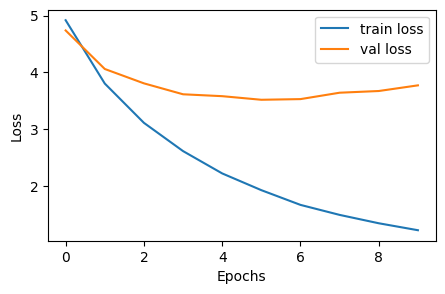

In [111]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(5, 3))
ax = fig.add_subplot(1, 1, 1)
ax.plot(train_losses, label="train loss")
ax.plot(val_losses, label="val loss")
plt.legend()
ax.set_xlabel("Epochs")
ax.set_ylabel("Loss")

In [67]:
# Test set
model.load_state_dict(torch.load(save_path))
test_loss = val_step(model, test_dataloader, criterion, test_loader_length)

print(f'| Test Loss: {test_loss:.3f} | Test PPL: {math.exp(test_loss):7.3f} |')

| Test Loss: 3.069 | Test PPL:  21.521 |


In [68]:
# Inference: Test on some random news. Note here we have source and target. Usually we will have jsut source during inference
sample[0], sample[1]

('Two young, White males are outside near many bushes.',
 'Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.')

In [69]:
src_text = transforms_pipe[SRC_LANGUAGE](sample[0]).to(device)
src_text

tensor([   2,   19,   25,   15, 1129,  861,   17,   55,   80,  343, 1359,    5,
           3], device='cuda:0')

In [70]:
target_text = transforms_pipe[TARGET_LANGUAGE](sample[1]).to(device)
target_text

tensor([   2,   21,   85,  257,   31,   89,   23,   99,    7,   16,  105,    0,
        3497,    4,    3], device='cuda:0')

In [71]:
src_text = src_text.reshape(-1, 1) # because bs is 1

In [72]:
target_text = target_text.reshape(-1, 1)

In [73]:
src_text.shape, target_text.shape

(torch.Size([13, 1]), torch.Size([15, 1]))

In [75]:
src_len = torch.tensor([src_text.size(0)]).to(dtype=torch.int64)
src_len

tensor([13])

In [76]:
model.load_state_dict(torch.load(save_path))

model.eval()
with torch.no_grad():
    output, attentions = model(src_text, src_len, target_text, 0) # turn off teacher forcing, auto regressive in inference

In [77]:
output.shape # (target_seq_len, bs, target_output_dim)

torch.Size([15, 1, 6464])

In [78]:
# Since batch size is 1, we just take off that dimension
output = output.squeeze(1)

In [79]:
output.shape

torch.Size([15, 6464])

In [80]:
# We shall remove the first token since it's zeroes anyway
output = output[1:]
output.shape # (target_seq_len-1, target_output_dim)

torch.Size([14, 6464])

In [81]:
# Then we just take the top token with highest probabilities - greedy
output_max = output.argmax(dim=1) # returns max indices # (target_seq_len-1)

In [83]:
output_max.shape

torch.Size([14])

In [82]:
output_max

tensor([ 21,  85,  31,   7,   0,  49, 136,   8,  36, 105,  24, 339,   4,   3],
       device='cuda:0')

In [84]:
# Get the mapping of the target language
mapping = vocab_transform[TARGET_LANGUAGE].get_itos()
for token in output_max:
    print(mapping[token.item()])

Zwei
junge
Männer
in
<unk>
stehen
draußen
,
während
Nähe
von
Bäumen
.
<eos>


### Attention Map
Let's display the attentions to understand how the source text links with the generated text

In [86]:
attentions.shape

torch.Size([15, 1, 13])

In [87]:
src_tokens = ["<sos>"] + tokenization_transform[SRC_LANGUAGE](sample[0]) + ["<eos>"]
src_tokens

['<sos>',
 'Two',
 'young',
 ',',
 'White',
 'males',
 'are',
 'outside',
 'near',
 'many',
 'bushes',
 '.',
 '<eos>']

In [88]:
target_tokens = ["<sos>"] + [mapping[token.item()] for token in output_max]
target_tokens

['<sos>',
 'Zwei',
 'junge',
 'Männer',
 'in',
 '<unk>',
 'stehen',
 'draußen',
 ',',
 'während',
 'Nähe',
 'von',
 'Bäumen',
 '.',
 '<eos>']

In [94]:
import matplotlib.ticker as ticker

def display_attention(sentence, translation, attention):
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)
    attn = attention.squeeze(dim=1).cpu().detach().numpy()

    cax = ax.matshow(attn, cmap="bone")

    ax.tick_params(labelsize=10)

    x_ticks = [''] + sentence
    y_ticks = [''] + translation
    ax.set_xticklabels(x_ticks, rotation=45)
    ax.set_yticklabels(y_ticks)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))

    plt.show()
    plt.close()


<ipython-input-94-b07ea9b703ec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_ticks, rotation=45)
<ipython-input-94-b07ea9b703ec>:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(y_ticks)


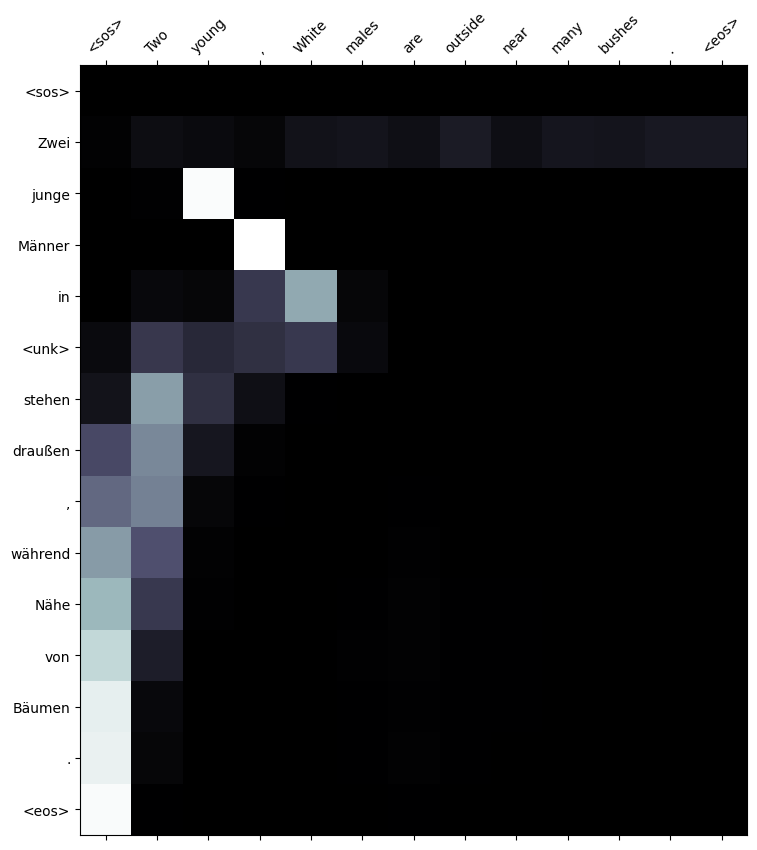

In [95]:
display_attention(src_tokens, target_tokens, attentions)

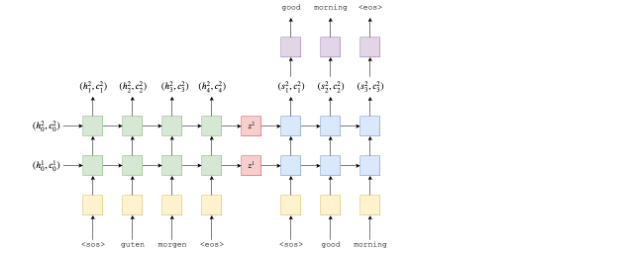

LSTM Encoder decoder outputs hidden encoder context vector and cell state and previous hidden state. This is also example of having more than 1 layer

In [ ]:
# Self
import torch, torchtext

from torchtext.datasets import Multi30k
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator

from torch import nn as nn
from torch.utils.data import DataLoader
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

import torch.optim as optim

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import time
import os

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Data
dataset = Multi30k(split="train", language_pair=("en", "de"))
total_length = len(list(iter(dataset)))
train, val, test = dataset.random_split(total_length, weights={"train": 0.7, "val": 0.2, "test": 0.1}, seed=SEED)

SRC_LANGUAGE = "en"
TARGET_LANGUAGE = "de"

token_transform = {}
src_tokenizer = get_tokenizer("spacy", "en_core_web_sm")
target_tokenizer = get_tokenizer("spacy", "de_news_web_sm")
token_transform[SRC_LANGUAGE] = src_tokenizer
token_transform[TARGET_LANGUAGE] = target_tokenizer

def yield_tokens(data, lang):
    lang_idx = {SRC_LANGUAGE: 0, TARGET_LANGUAGE: 1}
    for sample in data:
        yield token_transform[lang](sample[lang_idx[lang]])

vocab_transform = {}
specials = ["<unk>", "<pad>", "<sos>", "<eos>"]
UNK_IDX, PAD_IDX, SOS_IDX, EOS_IDX = 0, 1, 2, 3
for ln in [SRC_LANGUAGE, TRG_LANGUAGE]:
    vocab_transform[ln] = build_vocab_from_iterator(yield_tokens(train, ln), min_freq=2, specials=specials, special_first=True)

for ln in [SRC_LANGUAGE, TRG_LANGUAGE]:
    vocab_transform[ln].set_default_index(UNK_IDX)

src_vocab = len(vocab_transform[SRC_LANGUAGE])
target_vocab = len(vocab_transform[TARGET_LANGUAGE])

def sequence_transforms(*transforms):
    def func(input_text):
        for transform in transforms:
            transformed_text = transform(input_text)
        return transformed_text
    return func

def tensor_transform(token_ids):
    return torch.cat((torch.tensor([SOS_IDX]),
                     torch.tensor(token_ids),
                     torch.tensor([EOS_IDX])))

text_transforms = {}
for ln in [SRC_LANGUAGE, TARGET_LANGUAGE]:
    text_transforms[ln] = sequence_transforms(token_transform[ln],
                                              vocab_transform[ln],
                                              tensor_transform)

def collate_fn(batch):
    srcs, lengths, targets = [], [], []
    for src, target in batch:
        processed_src = text_transforms[SRC_LANGUAGE](src.rstrip("\n"))
        srcs.append(processed_src)
        lengths.append(processed_src.size(0))
        processed_target = text_transforms[TARGET_LANGUAGE](target.rstrip("\n"))
        targets.append(processed_target)
    srcs = pad_sequence(srcs, padding_value=PAD_IDX)
    targets = pad_sequence(targets, padding_value=PAD_IDX)
    return srcs, torch.tensor(lengths, dtype=torch.int64), targets


class Encoder(nn.module):
    def __init__(self, input_dim, embed_dim, hidden_dim, dropout):
        super().__init__()
        self.embeddings = nn.Embedding(input_dim, embed_dim, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(embed_dim, hidden_dim, num_layers=1, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, src_len):
        embeds = self.dropout(self.embeddings(src))
        packed_embeds = pack_padded_sequence(embeds, src_len.to("cpu"), enforce_sorted=False)
        packed_outputs, hidden = self.rnn(packed_embeds)
        outputs, _ = pad_packed_sequence(packed_outputs)
        hidden = torch.tanh(self.fc(torch.cat((hidden[-2, :, :], hidden[-1, :, :]), dim=1)))
        return outputs, hidden


class Attention(nn.module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.v = nn.Linear(hidden_dim, 1, bias=False)
        self.W = nn.Linear(hidden_dim, hidden_dim)
        self.U = nn.Linear(hidden_dim * 2, hidden_dim)

    def forward(self, encoder_outputs, hidden, mask):
        src_seq_len = encoder_outputs.shape[0]
        bs = encoder_outputs.shape[1]
        hidden = hidden.unsqueeze(dim=1).repeat(1, src_seq_len, 1)
        encoder_outputs = encoder_outputs(1, 0, 1)
        attn = self.v(torch.tanh(self.W(hidden) + self.U(encoder_outputs))).squeeze(dim=2)
        attn = attn.masked_fill(mask, -1e10)  # fills the true value with small value
        return F.softmax(attn, dim=1)


class Decoder(nn.module):
    def __init__(self, output_dim, embed_dim, hidden_dim, attention):
        super().__init__()
        self.embeddings = nn.Embedding(output_dim, embed_dim)
        self.rnn = nn.GRU((hidden_dim * 2) + embed_dim, hidden_dim, num_layers=1, bidirectional=False)
        self.fc = nn.Linear((hidden_dim * 2) + embed_dim + hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)
        self.attention = attention

    def forward(self, encoder_outputs, hidden, target, mask):
        target = target.unsqueeze(dim=0)
        embeds = self.dropout(self.embeddings(target))
        attn_weights = self.attention(encoder_outputs, hidden, mask)
        attn_weights = attn_weights.unsqueeze(dim=1)
        encoder_outputs = encoder_outputs.permute(1, 0, 2)
        weighted_sum = torch.bmm(attn_weights, encoder_outputs)
        weighted_sum = weighted_sum.permute(1, 0, 2)
        rnn_input = torch.cat((embeds, weighted_sum), dim=2)
        output, hidden = self.rnn(rnn_input, hidden.unsqueeze(dim=0))
        embeds, output, weighted_sum = embeds.squeeze(dim=0), output.squeeze(dim=0), weighted_sum.squeeze(dim=0)
        prediction = self.fc(torch.cat((output, embeds, weighted_sum), dim=1))
        return prediction, hidden.squeeze(dim=0), attn.squeeze(dim=1)


class Seq2SeqPackedAttnModel(nn.module):
    def __init__(self, encoder, decoder, src_pad_idx, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_pad_idx = src_pad_idx
        self.device = device

    def create_mask(self, src):
        mask = (src == self.src_pad_idx).permute(1, 0)
        return mask

    def forward(self, src, src_len, target, teacher_forcing_ratio=0.5):
        bs = src.shape[1]
        target_vocab_size = self.decoder.output_dim
        target_len = target.shape[-1]

        outputs = torch.zeros(target_len, bs, target_vocab_size).to(self.device)
        attns = torch.zeros(target_len, bs, src.shape[0]).to(self.device)

        encoder_outputs, hidden = self.encoder(src, src_len)
        mask = self.create_mask(src)

        input_ = target[0, :]

        for t in range(1, target_len):
            output, hidden, attn = self.decoder(encoder_outputs, hidden, input_, mask)
            outputs[t] = output
            attns[t] = attn

            teacher_forcing = random.random() < teacher_forcing_ratio
            top1 = output.argmax(dim=1)
            input_ = target[t] if teacher_forcing else top1
        return outputs, attns

def train_step(model, train_dataloader, optimizer, criterion, loader_length, clip):
    epoch_loss = 0.0
    model.train()
    for src, src_len, target in train_dataloader:
        src = src.to(device)
        target = target.to(device)
        optimizer.zero_grad()
        output, attn = model(src, src_len, target, 0.5)
        output_dim = output.shape[-1]
        output = output[1:].view(-1, output_dim)
        target = target[1:].view(-1)
        loss = criterion(output, target)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        epoch_loss += loss.item()
    return epoch_loss / loader_length


def val_step(model, val_dataloader, criterion, loader_length):
    epoch_loss = 0.0
    model.eval()
    with torch.no_grad():
        for src, src_len, target in val_dataloader:
            src = src.to(device)
            target = target.to(device)
            output, attn = model(src, src_len, target, 0)
            output_dim = output.shape[-1]
            output = output[1:].view(-1, output_dim)
            target = target[1:].view(-1)
            loss = criterion(output, target)
            epoch_loss += loss.item()
    return epoch_loss / loader_length

def elapsed_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins*60))
    return elapsed_mins, elapsed_secs

def count_params(m):
    params = [p.numel() for p in m.parameters() if p.requires_grad]
    for item in params:
        print(f'{item:>6}')
    print(f'______\n{sum(params):>6}')

def init_params(m):
    for name, param in m.named_parameters():
        if "weight" in name:
            nn.init.normal_(param.data, mean=0, std=0.01)
        elif "bias" in name:
            nn.init.constant_(param.data, 0)
# Training
BATCH_SIZE = 64
train_dataloader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_dataloader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_dataloader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
train_loader_len = len(list(iter(train_dataloader)))
val_loader_len = len(list(iter(val_dataloader)))
test_loader_len = len(list(iter(test_dataloader)))

optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

input_dim = len(vocab_transform[SRC_LANGUAGE])
output_dim = len(vocab_transform[TARGET_LANGUAGE])
embed_dim = 256
hidden_dim = 512
dropout = 0.5
encoder = Encoder(input_dim, embed_dim, hidden_dim, dropout)
attention = Attention(hidden_dim)
decoder = Decoder(output_dim, embed_dim, hidden_dim, attention)
model = Seq2SeqPackedAttnModel(encoder, decoder, PAD_IDX, teacher_forcing_ratio=0.5)
model.apply(init_params)
model.to(device)
clip = 1

best_loss = float("inf")
save_path = f"/content/{model.__class__.__name__}.pt"
epochs = 10
train_losses, val_losses = [], []
for epoch in range(epochs):
    start_time = time.time()
    train_loss = train_step(model, train_dataloader, optimizer, criterion, train_loader_len, clip)
    val_loss = val_step(model, val_dataloader, criterion, val_loader_len)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_loss:
        torch.save(model.state_dict(), save_path)
    end_time = time.time()
    elapsed_mins, elapsed_secs = elapsed_time(start_time, end_time)
    print(f"Epoch: {epoch+1:02} | Time: {elapsed_mins}m {elapsed_secs}s.")
    print(f"\tTrain Loss:{train_loss:.3f} | Train PPL:{math.exp(train_loss):7.3f}")
    print(f"\tVal Loss:{val_loss:.3f} | Val PPL:{math.exp(val_loss):7.3f}")

# Plotting
fig = plt.figure(figsize=(5, 3))
ax = fig.add_subplot(1, 1, 1)
ax.plot(train_losses, label="Train loss")
ax.plot(val_losses, label="Val loss")
plt.legend()
ax.set_xlabel('Epochs')
ax.set_ylabel('Losses')

# Testing
model.load_state_dict(torch_load(save_path))
test_loss = val_step(model, test_dataloader, criterion, test_loader_len)
print(f"\tTest Loss:{test_loss:.3f} | Train PPL:{math.exp(test_loss):7.3f}")

# Inference
sample = next(iter(train))
src = text_transform[SRC_LANGUAGE](sample[0]).to(device)
src_len = torch.tensor([src.shape[0]]).to(dtype=torch.int64)
target = text_transform[TARGET_LANGUAGE](sample[1]).to(device)
src = src.reshape(-1, 1)
target = target.reshape(-1, 1)
model.load_state_dict(torch.load(save_path))
model.eval()
with torch.no_grad():
    output, attns = model(src, src_len, target, teacher_forcing_ratio=0)

output = output.squeeze(dim=1)
output = output[1:]
output_max = output.argmax(dim=1)
target = target[1:]
mapping = vocab_transform[TARGET_LANGUAGE].get_itos()
src_tokens = ["<sos>"] + token_transform[SRC_LANGUAGE](sample[0]) + ["<eos>"]
target_tokens = ["<sos>"] + [mapping[token].item() for token in output_max]

# Attention Map
def display_attention(sentence, translation, attns):
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111)
    attns = attns.squeeze(dim=1).cpu().detach().numpy()
    ax.matshow(attn, cmap=bone)
    ax.tick_parans(labelsize=10)
    xticks = [""] + sentence
    yticks = [""] + translation
    ax.set_xticklabels(xticks, rotation=45)
    ax.set_yticklabels(yticks)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
    plt.show()
    plt.close()

display_attention(src_tokens, target_tokens, attns)